# 호출 한도와 비용 상한

이 절은 모델을 부르기 전에 호출 수와 예상 비용을 예약합니다.
정한 한도를 넘는 요청은 모델을 부르기 전에 멈춥니다.

**이 노트북에서 할 일**

1. 한 대화의 호출 한도·비용 상한과 요청 하나의 예상 비용을 정합니다.
2. 예산 딕셔너리를 만드는 함수와, 부르기 전에 예약하는 함수를 만듭니다.
3. 한도를 보지 않는 흐름이 한도를 넘는 요청까지 보낼 목록에 담는 것을 봅니다(Before).
4. 부르기 전에 예약하면 한도를 넘는 요청이 모델에 가지 않는 것을 봅니다(After).

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
모델 `gpt-5.4-mini`에 보내는 요청은 7절 두 번과 9절 한 번, 모두 세 번입니다.
임베딩 요청은 없습니다.
노트북을 한 번 실행하는 요금은 요금표로 어림해 미화 0.01달러 아래입니다.
이 값은 3절에서 정할 요청 하나의 예상 비용 0.002달러와 다르고, 실제 청구 금액과도 다를 수 있습니다.

읽는 파일은 이 챕터 자료 파일 `data/retrieved-documents.json` 하나입니다.
새로 쓰는 파일은 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 약 5초 만에 끝났습니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~7절을 읽습니다.
한도를 정하고, 예약 함수를 만들고, 한도를 보지 않는 흐름을 보는 자리입니다.
7절은 부르기 전에 예약하며 질문을 보내는 자리입니다.
8절 손 확인과 9절 값 바꿔 보기는 실습 시간에 실행합니다.

실습 폴더 `labs/part4/ch16-guardrails`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

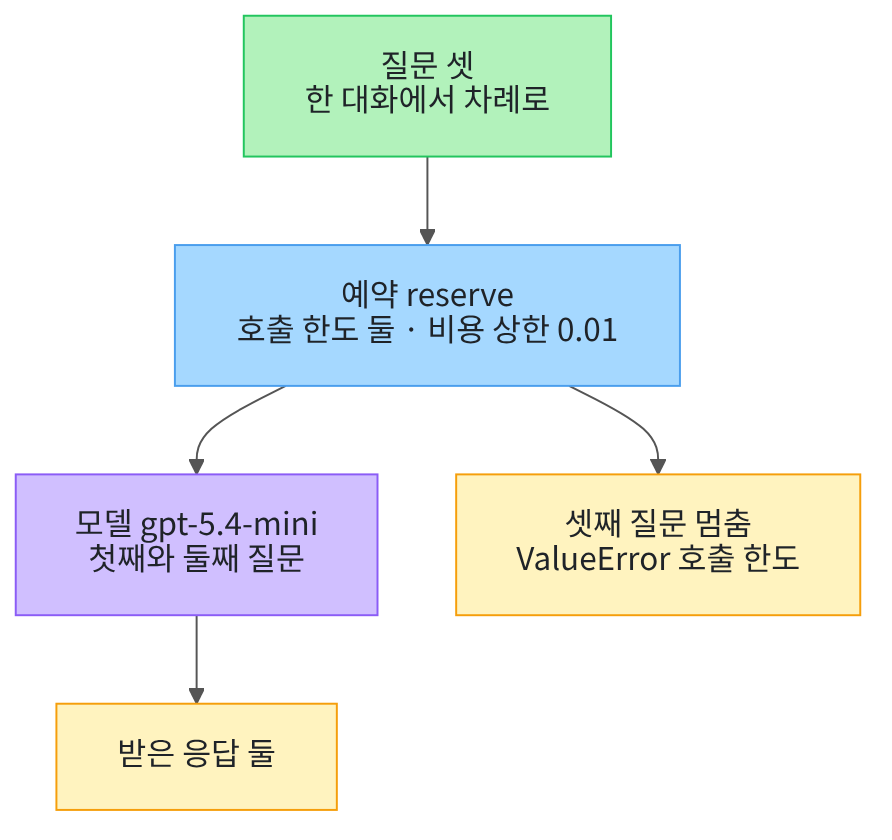

위에서 아래로 읽습니다. 초록 질문 셋이 파란 예약을 지나 화살표 둘로 나뉩니다.
왼쪽은 보라 모델을 거쳐 응답 둘을 받고, 오른쪽은 셋째 질문이 노란 상자에서 멈춥니다.

## 1. 준비

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0


langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.1`이 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-23에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름 넷을 불러옵니다.
모듈 `math`는 Ch 15 06절에서 `math.ceil`을 쓸 때 불러온 모듈입니다.
이 절은 그 안의 함수 `math.isfinite`를 처음 씁니다.

In [2]:
# 파일을 읽을 이름, 수학 기능 묶음, 모델을 만들 이름을 불러옵니다
import json
import math
import os

from langchain.chat_models import init_chat_model

print("불러온 이름:", "json", "math", "os", "init_chat_model")

불러온 이름: json math os init_chat_model


**결과 읽기** — 출력 줄 `불러온 이름: json math os init_chat_model`로 이름 넷을 불러왔습니다.
이 절은 도구 파일 `guardrails.py`에서 가져오는 함수가 없습니다.
호출 한도와 비용 상한을 다루는 함수는 이 절에서 처음 만듭니다.

## 2. 키와 모델 준비

이 절은 7절에서 두 번, 9절에서 한 번 모델 `gpt-5.4-mini`를 부릅니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도 답 문장이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-23에 이 모델로 실행한 결과입니다.

## 3. 자료와 이 절에서 정한 값

먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.
01·02절과 같은 자리 찾기 셀입니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch16-guardrails/data"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위:` 뒤에 점 하나나 위로 올라가는 자리가 보입니다.

다음 셀은 01·02절과 같은 자료 파일을 읽고 안내 문서 하나를 고릅니다.
이 절의 질문은 모두 이 문서로 답할 수 있습니다.

In [6]:
# 자료 파일을 읽고 이 절의 검색 결과로 안내 문서 E01 하나만 고릅니다(읽기만 합니다)
data_path = root_path + "/labs/part4/ch16-guardrails/data"
with open(data_path + "/retrieved-documents.json", encoding="utf-8") as file:
    all_documents = json.loads(file.read())
retrieved = []
for document in all_documents:
    if document["doc_id"] == "E01":
        retrieved.append(document)
print("자료 파일의 문서 수:", len(all_documents))
print("이번 검색 결과의 문서 수:", len(retrieved))

자료 파일의 문서 수: 2
이번 검색 결과의 문서 수: 1


**결과 읽기** — 출력 줄 `자료 파일의 문서 수: 2`로 자료 파일의 문서는 둘입니다.
출력 줄 `이번 검색 결과의 문서 수: 1`로 이 절은 안내 문서 하나만 씁니다.

다음 셀은 01·02절과 같은 시스템 메시지 글과 검색 문서 한 줄을 적습니다.

In [7]:
# 01·02절과 같은 지킬 말과 검색 문서 한 줄입니다
system_text = "검색 문서에 있는 사실만 써서 한국어 한 문장으로 답하세요. 답 끝에 쓴 문서의 출처를 [문서ID p.쪽] 꼴로 적으세요."
document = retrieved[0]
document_line = "검색 문서 " + document["doc_id"] + " " + str(document["page"]) + "쪽: " + document["text"]
print("지킬 말:")
print(system_text)
print("검색 문서 한 줄:")
print(document_line)

지킬 말:
검색 문서에 있는 사실만 써서 한국어 한 문장으로 답하세요. 답 끝에 쓴 문서의 출처를 [문서ID p.쪽] 꼴로 적으세요.
검색 문서 한 줄:
검색 문서 E01 1쪽: 미르시립도서관은 매주 월요일과 법정 공휴일에 휴관합니다. 공휴일이 월요일과 겹치면 다음 날인 화요일에도 휴관합니다.


**결과 읽기** — 라벨 줄 `지킬 말:` 아래 줄이 시스템 메시지로 보낼 글입니다.
라벨 줄 `검색 문서 한 줄:` 아래 줄이 질문과 함께 보낼 문서입니다.
두 글 모두 01·02절과 같습니다.
출력 라벨과 코드 주석의 「지킬 말」은 시스템 메시지 글을 부르는 이름입니다.
Ch 8 03절의 지킬 말(꼭 남아야 할 말 목록)과는 다른 뜻입니다.

다음 셀은 이 절에서 정한 값 셋을 적습니다.
호출 한도(call limit)는 한 대화에서 모델을 부를 수 있는 가장 많은 횟수입니다.
비용 상한(cost cap)은 한 대화에서 쓸 수 있는 예상 비용 합계의 가장 큰 값입니다.
예상 비용은 요청을 보내기 전에 어림한 비용이고 청구 금액이 아닙니다.

Ch 15 06절처럼 예산은 요청 한 번이 아니라 대화 하나를 단위로 셉니다.
요청 하나의 예상 비용 0.002달러는 요금표로 센 값이 아니라 이 절에서 정한 값입니다.

In [8]:
# 이 절에서 정한 값입니다: 한 대화의 호출 한도와 비용 상한, 요청 하나의 예상 비용
max_calls = 2
max_cost_usd = 0.01
estimated_cost = 0.002
print("호출 한도:", max_calls)
print("비용 상한(달러):", max_cost_usd)
print("요청 하나의 예상 비용(달러):", estimated_cost)

호출 한도: 2
비용 상한(달러): 0.01
요청 하나의 예상 비용(달러): 0.002


**결과 읽기** — 출력 줄 `호출 한도: 2`로 한 대화에서 모델을 두 번까지 부릅니다.
출력 줄 `비용 상한(달러): 0.01`이 예상 비용 합계의 상한입니다.
출력 줄 `요청 하나의 예상 비용(달러): 0.002`로 요청마다 같은 값을 씁니다.

세 값은 한도에 걸리는 모습이 잘 보이게 정한 값입니다.
실제 서비스라면 Ch 6 06절 요금표처럼 토큰 수와 요금으로 예상 비용을 어림합니다.

## 4. 질문 셋과 보낼 메시지

한 대화에서 사용자가 질문 셋을 차례로 보냈다고 해 봅니다.
세 질문 모두 안내 문서로 답할 수 있습니다.
정한 호출 한도가 2라서 셋째 질문은 한도를 넘습니다.

In [9]:
# 한 대화에서 사용자가 차례로 보낸 질문 셋입니다(이 절에서 손으로 적었습니다)
questions = [
    "도서관 휴관일은 언제인가요?",
    "공휴일이 월요일과 겹치면 언제 쉬나요?",
    "법정 공휴일에도 문을 여나요?",
]
print("질문 수:", len(questions))

질문 수: 3


**결과 읽기** — 출력 줄 `질문 수: 3`으로 질문은 셋입니다.
첫 질문은 01·02절과 같은 휴관일 질문입니다.

다음 셀은 질문 하나로 보낼 메시지를 만드는 함수입니다.
메시지 모양은 01·02절과 같은 역할 딕셔너리 두 개입니다.
시스템 메시지 글과 검색 문서 한 줄은 3절에서 적은 값을 씁니다.

In [10]:
# 질문 하나로 지킬 말과 사용자 메시지, 두 역할 딕셔너리를 만듭니다
def build_messages(question):
    user_text = "질문: " + question + "\n" + document_line
    messages = [
        {"role": "system", "content": system_text},
        {"role": "user", "content": user_text},
    ]
    return messages

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_messages`는 질문 하나를 받아 메시지 목록 하나를 내놓습니다.
사용자 메시지는 「질문: 」 뒤에 질문을 적고, 줄을 바꿔 검색 문서 한 줄을 붙입니다.

다음 셀은 첫 질문으로 메시지를 만들어 모양을 봅니다.
이 셀은 모델에 보내지 않습니다.

In [11]:
# 첫 질문으로 메시지를 만들어 모양을 봅니다(보내지는 않습니다)
first_messages = build_messages(questions[0])
print("메시지 수:", len(first_messages))
print("역할:", first_messages[0]["role"], first_messages[1]["role"])
print("사용자 메시지:")
print(first_messages[1]["content"])

메시지 수: 2
역할: system user
사용자 메시지:
질문: 도서관 휴관일은 언제인가요?
검색 문서 E01 1쪽: 미르시립도서관은 매주 월요일과 법정 공휴일에 휴관합니다. 공휴일이 월요일과 겹치면 다음 날인 화요일에도 휴관합니다.


**결과 읽기** — 출력 줄 `메시지 수: 2`와 `역할: system user`로 역할 딕셔너리 두 개가 만들어졌습니다.
라벨 줄 `사용자 메시지:` 아래 두 줄이 모델에게 갈 사용자 메시지입니다.

## 5. 예산 딕셔너리와 예약

예약(reserve)은 모델을 부르기 전에 호출 한 번과 예상 비용을 미리 적어 두는 일입니다.
표를 내야 개찰구를 지나가듯, 예약이 되어야 모델을 부릅니다.
예약한 양은 예산(budget) 딕셔너리에 적습니다.
예산 딕셔너리에는 두 한도와 지금까지 예약한 호출 수·예상 비용이 함께 들어갑니다.

예상 비용 자리에 보통 숫자가 아닌 값이 들어올 수도 있습니다.
값 `float("nan")`은 숫자가 아니라는 뜻(not a number)의 특별한 값입니다.
값 `float("inf")`는 끝없이 큰 값입니다.
함수 `math.isfinite(값)`은 값이 nan도 inf도 아닌 끝이 있는 숫자이면 `True`를 내놓습니다.

In [12]:
# nan과 inf를 만들어 보고, math.isfinite가 끝이 있는 숫자인지 가리는 모습을 봅니다
not_a_number = float("nan")
infinity = float("inf")
print("0.002는 끝이 있는 숫자:", math.isfinite(estimated_cost))
print("nan은 끝이 있는 숫자:", math.isfinite(not_a_number))
print("inf는 끝이 있는 숫자:", math.isfinite(infinity))
print("nan이 비용 상한보다 큰가:", not_a_number > max_cost_usd)

0.002는 끝이 있는 숫자: True
nan은 끝이 있는 숫자: False
inf는 끝이 있는 숫자: False
nan이 비용 상한보다 큰가: False


**결과 읽기** — 출력 줄 `0.002는 끝이 있는 숫자: True`로 정한 예상 비용은 보통 숫자입니다.
출력 줄 `nan은 끝이 있는 숫자: False`와 `inf는 끝이 있는 숫자: False`로 두 값은 걸러집니다.
출력 줄 `nan이 비용 상한보다 큰가: False`를 눈여겨봅니다.
값 nan은 어떤 값과 견줘도 크다는 결과가 나오지 않습니다.

그래서 「상한보다 크면 막기」만 두면 nan은 그 검사를 그냥 지나갑니다.
다음 두 함수는 이런 값을 `math.isfinite`로 먼저 막습니다.

다음 셀은 예산 딕셔너리를 만드는 함수입니다.
호출 한도가 1보다 작거나, 비용 상한이 끝이 있는 양수가 아니면 `ValueError`를 냅니다.
조건 `not A or B`에서 `not`은 바로 뒤 조건 A에만 붙습니다.
그래서 「A가 아니거나 B이면」이라는 뜻입니다.

In [13]:
# 호출 한도와 비용 상한을 담은 예산 딕셔너리를 만듭니다
def make_budget(max_calls, max_cost_usd):
    if max_calls < 1:
        raise ValueError("호출 한도는 1 이상이어야 합니다.")
    if not math.isfinite(max_cost_usd) or max_cost_usd <= 0:
        raise ValueError("비용 상한은 끝이 있는 양수여야 합니다.")
    return {"max_calls": max_calls, "max_cost_usd": max_cost_usd, "calls": 0, "cost_usd": 0.0}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `make_budget`은 두 한도를 받아 칸 넷짜리 딕셔너리를 내놓습니다.
칸 `calls`는 지금까지 예약한 호출 수이고, 칸 `cost_usd`는 지금까지 예약한 예상 비용 합계입니다.
두 칸 모두 0에서 시작합니다.

다음 셀은 3절에서 정한 값으로 예산을 하나 만들어 봅니다.

In [14]:
# 3절에서 정한 값으로 예산을 하나 만들고 네 칸을 봅니다
sample_budget = make_budget(max_calls, max_cost_usd)
print("새 예산:", sample_budget)

새 예산: {'max_calls': 2, 'max_cost_usd': 0.01, 'calls': 0, 'cost_usd': 0.0}


**결과 읽기** — 출력 줄 `새 예산: {'max_calls': 2, 'max_cost_usd': 0.01, 'calls': 0, 'cost_usd': 0.0}`이 새 예산입니다.
한도 칸 둘은 3절 값과 같고, 예약한 양 칸 둘은 0입니다.

다음 셀은 예약 함수 `reserve`입니다.
검사 셋을 차례로 하고, 모두 지나야 예산 칸을 고칩니다.
첫째는 예상 비용이 끝이 있는 0 이상 값인지 봅니다.
둘째는 호출 수에 하나를 더해도 한도 안인지, 셋째는 예상 비용을 더해도 상한 안인지 봅니다.

칸 고치기는 `budget["calls"] = budget["calls"] + 1`처럼 씁니다.
오른쪽에서 지금 값에 1을 더한 뒤 같은 칸에 다시 넣습니다.
이 함수는 아무것도 내놓지 않고 받은 딕셔너리의 칸만 고칩니다.

In [15]:
# 모델을 부르기 전에 호출 한 번과 예상 비용을 예산에 예약합니다
def reserve(budget, estimated_cost_usd):
    if not math.isfinite(estimated_cost_usd) or estimated_cost_usd < 0:
        raise ValueError("예상 비용은 끝이 있는 0 이상 값이어야 합니다.")
    if budget["calls"] + 1 > budget["max_calls"]:
        raise ValueError("호출 한도를 넘습니다.")
    if budget["cost_usd"] + estimated_cost_usd > budget["max_cost_usd"]:
        raise ValueError("비용 상한을 넘습니다.")
    budget["calls"] = budget["calls"] + 1
    budget["cost_usd"] = budget["cost_usd"] + estimated_cost_usd

**결과 읽기** — 정의 셀이라 출력이 없습니다.
검사 하나라도 걸리면 `raise`에서 멈추고 아래 줄은 실행되지 않습니다.
그래서 막힌 예약은 예산 칸을 바꾸지 않습니다.
함수에 넘긴 딕셔너리는 함수 밖의 딕셔너리와 같은 것입니다.
함수 안에서 고친 칸이 밖에서도 보입니다.

다음 셀은 앞에서 만든 새 예산에 한 번 예약해 봅니다.
모델은 부르지 않습니다.

In [16]:
# 새 예산에 한 번 예약하고 칸이 어떻게 바뀌었는지 봅니다(모델은 부르지 않습니다)
reserve(sample_budget, estimated_cost)
print("예약 한 번 뒤 예산:", sample_budget)

예약 한 번 뒤 예산: {'max_calls': 2, 'max_cost_usd': 0.01, 'calls': 1, 'cost_usd': 0.002}


**결과 읽기** — 출력 줄 `예약 한 번 뒤 예산: {'max_calls': 2, 'max_cost_usd': 0.01, 'calls': 1, 'cost_usd': 0.002}`에서 두 칸이 바뀌었습니다.
칸 `calls`는 1이 되었고 칸 `cost_usd`는 0.002가 되었습니다.
함수 `reserve`는 아무것도 내놓지 않았지만 넘긴 딕셔너리의 칸이 바뀌었습니다.

## 6. 한도를 보지 않는 흐름 (Before)

Before 셀은 예산을 만들어 두고도 쓰지 않는 흐름입니다.
질문마다 메시지를 만들어 보낼 목록에 그대로 담습니다.
이 흐름은 보내기 직전에서 멈추고 실제로 모델에 보내지는 않았습니다.
목록에 담은 요청 수와 예상 비용 합계를 셉니다.

In [17]:
# 한도를 보지 않는 흐름입니다: 질문마다 메시지를 만들어 보낼 목록에 담습니다(보내지는 않습니다)
outbox = []
planned_cost = 0.0
for question in questions:
    messages = build_messages(question)
    outbox.append(messages)
    planned_cost = planned_cost + estimated_cost
print("보낼 목록의 요청 수:", len(outbox))
print("보낼 목록의 예상 비용 합계(달러):", planned_cost)

보낼 목록의 요청 수: 3
보낼 목록의 예상 비용 합계(달러): 0.006


**결과 읽기** — 출력 줄 `보낼 목록의 요청 수: 3`으로 질문 셋이 모두 보낼 목록에 들어갔습니다.
출력 줄 `보낼 목록의 예상 비용 합계(달러): 0.006`은 비용 상한 0.01 안입니다.
이 흐름은 호출 수도 예상 비용도 한도와 견주지 않았습니다.

다음 셀은 보낼 목록을 3절에서 정한 호출 한도와 견줍니다.

In [18]:
# 보낼 목록을 3절에서 정한 호출 한도와 견줘 한도를 넘는 요청을 셉니다
over_count = len(outbox) - max_calls
print("정한 호출 한도:", max_calls)
print("한도를 넘는 요청 수:", over_count)
print("한도를 넘는 첫 요청의 질문:", questions[max_calls])

정한 호출 한도: 2
한도를 넘는 요청 수: 1
한도를 넘는 첫 요청의 질문: 법정 공휴일에도 문을 여나요?


**결과 읽기** — 출력 줄 `한도를 넘는 요청 수: 1`이 이 흐름의 결함입니다.
라벨 `한도를 넘는 첫 요청의 질문:` 뒤가 셋째 질문입니다.
이대로 보내면 호출 한도 2를 넘어 모델을 세 번 부릅니다.

한도를 적어 두기만 하고 보내는 코드가 보지 않으면 한도는 아무것도 막지 못합니다.

## 7. 부르기 전에 예약하는 흐름 (After)

After 셀은 질문을 보내기 전마다 `reserve`로 예약합니다.
예약이 막히면 모델을 부르지 않고 그 자리에서 멈춥니다.
먼저 예약과 모델 부르기를 한 함수로 묶습니다.

In [19]:
# 먼저 예약하고, 예약이 되면 그 질문을 모델에게 보냅니다(부를 때마다 모델 요청 1번)
def ask_with_budget(budget, question, estimated_cost_usd):
    reserve(budget, estimated_cost_usd)
    messages = build_messages(question)
    return model.invoke(messages)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `ask_with_budget`의 첫 줄이 예약입니다.
예약에서 `ValueError`가 나면 아래 두 줄은 실행되지 않아 모델을 부르지 않습니다.
예약이 되면 메시지를 만들어 모델에게 보내고 받은 응답을 내놓습니다.

다음 셀은 질문 목록을 차례로 보내는 함수입니다.
03절처럼 `try/except ValueError as error`로 오류를 받습니다.
예약이 막히면 막힌 질문과 까닭을 출력하고 그때까지 받은 응답 목록을 내놓습니다.

In [20]:
# 질문 목록을 차례로 보내다가 예약이 막히면 그 자리에서 멈춥니다
def ask_all(budget, questions, estimated_cost_usd):
    answers = []
    for question in questions:
        try:
            answers.append(ask_with_budget(budget, question, estimated_cost_usd))
        except ValueError as error:
            print("멈춘 질문:", question, "| 까닭:", error)
            break
    return answers

**결과 읽기** — 정의 셀이라 출력이 없습니다.
블록 `try` 안의 한 줄은 예약하고 받은 응답을 목록에 더합니다.
예약이 막히면 응답이 없으므로 목록에 아무것도 더하지 않습니다.
오류를 받은 뒤의 `break`는 남은 질문을 보지 않고 반복을 끝냅니다.
그래서 막힌 질문 뒤의 질문도 보내지 않습니다.

다음 셀은 새 예산으로 질문 셋을 보냅니다.
이 셀에서 모델 요청이 두 번 나가고, 셋째 질문은 예약에서 멈출 것입니다.

In [21]:
# 새 예산으로 질문 셋을 차례로 보냅니다(모델 요청 2번, 셋째 질문은 예약에서 멈춥니다)
budget = make_budget(max_calls, max_cost_usd)
answers = ask_all(budget, questions, estimated_cost)
print("모델에 보낸 요청 수:", len(answers))
print("예약한 호출 수:", budget["calls"])
print("예약한 예상 비용 합계(달러):", budget["cost_usd"])

멈춘 질문: 법정 공휴일에도 문을 여나요? | 까닭: 호출 한도를 넘습니다.
모델에 보낸 요청 수: 2
예약한 호출 수: 2
예약한 예상 비용 합계(달러): 0.004


**결과 읽기** — 첫 출력 줄 `멈춘 질문: 법정 공휴일에도 문을 여나요? | 까닭: 호출 한도를 넘습니다.`가 셋째 질문입니다.
출력 줄 `모델에 보낸 요청 수: 2`로 모델은 두 번만 불렸습니다.
출력 줄 `예약한 호출 수: 2`와 `예약한 예상 비용 합계(달러): 0.004`가 예산에 적힌 양입니다.

셋째 질문은 호출 수 검사에서 막혀 모델에 가지 않았습니다.
앞 6절 Before 셀에서는 `보낼 목록의 요청 수: 3`이었습니다.

다음 셀은 받은 답 둘을 봅니다.

In [22]:
# 받은 답을 번호와 함께 봅니다
print("받은 답:")
for i in range(len(answers)):
    print(i, "|", answers[i].text)

받은 답:
0 | 미르시립도서관은 매주 월요일과 법정 공휴일에 휴관하며, 공휴일이 월요일과 겹치면 다음 날인 화요일에도 휴관합니다 [E01 p.1]
1 | 공휴일이 월요일과 겹치면 다음 날인 화요일에도 쉽니다. [E01 p.1]


**결과 읽기** — 라벨 줄 `받은 답:` 아래 두 줄이 모델 답입니다.
번호 0은 첫 질문의 답이고, 번호 1은 둘째 질문의 답입니다.
셋째 질문의 답은 없습니다.

이 답은 모델이 쓴 글이라 여러분 실행에서는 문장이 다를 수 있습니다.
교재 출력을 만들며 새 커널로 두 번 실행했을 때도 둘째 답의 끝말이 달랐습니다.
이 절은 답 문장이 아니라 보낸 요청 수와 멈춘 질문을 봅니다.

다음 셀은 첫 응답의 실제 사용량을 봅니다.
Ch 6 06절처럼 응답의 `usage_metadata`에 입력·출력 토큰 수가 들어 있습니다.
이 값은 응답을 받은 뒤에야 알 수 있습니다.

In [23]:
# 첫 응답의 실제 사용량을 따로 봅니다: 예약할 때 쓴 예상 비용과는 다른 값입니다
first_usage = answers[0].usage_metadata
print("첫 응답 입력 토큰 수:", first_usage["input_tokens"])
print("첫 응답 출력 토큰 수:", first_usage["output_tokens"])
print("예약한 요청 하나의 예상 비용(달러):", estimated_cost)

첫 응답 입력 토큰 수: 122
첫 응답 출력 토큰 수: 53
예약한 요청 하나의 예상 비용(달러): 0.002


**결과 읽기** — 라벨 `첫 응답 입력 토큰 수:`와 `첫 응답 출력 토큰 수:` 뒤가 실제로 쓴 토큰 수입니다.
출력 줄 `예약한 요청 하나의 예상 비용(달러): 0.002`는 보내기 전에 정한 값입니다.
두 값은 서로 다른 것이라 섞지 않습니다.
이 절은 토큰 수로 비용을 다시 셈하지 않았습니다.

이번 실행에서는 입력 토큰 122개, 출력 토큰 53개였습니다.
교재 출력을 만들며 새 커널로 두 번 실행했을 때 두 값은 같았습니다.
그래도 출력 토큰 수는 답 문장에 따라 달라질 수 있습니다.

다음 셀은 두 흐름을 한 표로 나란히 봅니다.

In [24]:
# 두 흐름을 한 표로 나란히 봅니다
print("흐름 | 모델에 갈 요청 수 | 멈춘 질문 수")
print("한도를 보지 않는 흐름 |", len(outbox), "|", len(questions) - len(outbox))
print("예약하는 흐름 |", len(answers), "|", len(questions) - len(answers))

흐름 | 모델에 갈 요청 수 | 멈춘 질문 수
한도를 보지 않는 흐름 | 3 | 0
예약하는 흐름 | 2 | 1


**결과 읽기** — 라벨 줄 `흐름 | 모델에 갈 요청 수 | 멈춘 질문 수` 아래 두 줄이 두 흐름입니다.
출력 줄 `한도를 보지 않는 흐름 | 3 | 0`은 보낼 목록에 담은 수입니다.
출력 줄 `예약하는 흐름 | 2 | 1`은 실제로 보낸 수와 멈춘 수입니다.
두 흐름은 같은 질문 셋과 같은 한도를 썼고, 예약을 했는지만 달랐습니다.

## 8. 손으로 정한 값으로 확인하기

다음 셀은 잘못된 예상 비용 셋을 새 예산에 예약해 봅니다.
5절에서 만든 nan과 inf, 그리고 음수 -0.1입니다.
셋 모두 막혀야 하고 예산 칸은 그대로여야 합니다.
미리 정한 값이라 결과를 `assert`로 확인할 수 있습니다.

In [25]:
# 잘못된 예상 비용 셋을 예약해 봅니다(미리 정한 값이라 assert로 봅니다, 모델은 부르지 않습니다)
check_budget = make_budget(max_calls, max_cost_usd)
negative_cost = -0.1
print("예상 비용 | 막은 까닭")
for bad_cost in [not_a_number, infinity, negative_cost]:
    try:
        reserve(check_budget, bad_cost)
    except ValueError as error:
        print(bad_cost, "|", error)
assert check_budget["calls"] == 0
assert check_budget["cost_usd"] == 0.0

예상 비용 | 막은 까닭
nan | 예상 비용은 끝이 있는 0 이상 값이어야 합니다.
inf | 예상 비용은 끝이 있는 0 이상 값이어야 합니다.
-0.1 | 예상 비용은 끝이 있는 0 이상 값이어야 합니다.


**결과 읽기** — 라벨 줄 `예상 비용 | 막은 까닭` 아래 세 줄에서 세 값이 모두 막혔습니다.
까닭은 모두 `예상 비용은 끝이 있는 0 이상 값이어야 합니다.`입니다.
마지막 두 줄의 `assert`도 통과해 예약한 호출 수와 예상 비용은 0 그대로입니다.

## 9. 값 바꿔 보기 · 비용 상한 0.003

바꿀 값은 비용 상한 하나입니다.
0.01 대신 0.003으로 새 예산을 만들고 같은 질문 셋을 보냅니다.
호출 한도 2와 요청 하나의 예상 비용 0.002는 그대로입니다.

실행 전에 예상해 봅니다.
첫 질문은 예상 비용 0.002가 상한 안이라 보낼 것입니다.
둘째 질문은 합계가 0.004가 되어 상한 0.003을 넘으므로 멈출 것입니다.
이 셀에서 모델 요청은 한 번 나갈 것입니다.

In [26]:
# 바꿀 값은 비용 상한 하나입니다: 0.01 대신 0.003으로 같은 질문 셋을 보냅니다
small_cost_cap = 0.003
small_budget = make_budget(max_calls, small_cost_cap)
small_answers = ask_all(small_budget, questions, estimated_cost)
print("비용 상한(달러):", small_cost_cap)
print("모델에 보낸 요청 수:", len(small_answers))
print("예약한 예상 비용 합계(달러):", small_budget["cost_usd"])

멈춘 질문: 공휴일이 월요일과 겹치면 언제 쉬나요? | 까닭: 비용 상한을 넘습니다.
비용 상한(달러): 0.003
모델에 보낸 요청 수: 1
예약한 예상 비용 합계(달러): 0.002


**결과 읽기** — 첫 출력 줄에서 둘째 질문이 `비용 상한을 넘습니다.`로 멈췄습니다.
출력 줄 `모델에 보낸 요청 수: 1`로 모델은 한 번만 불렸습니다.
출력 줄 `예약한 예상 비용 합계(달러): 0.002`가 예산에 적힌 양입니다.

예상대로 이번에는 호출 수가 아니라 비용 상한이 둘째 질문을 막았습니다.
7절 출력에서는 셋째 질문이 `호출 한도를 넘습니다.`로 멈췄습니다.

## 정리

1. 한 대화의 호출 한도와 비용 상한을 예산 딕셔너리에 담고, 부르기 전에 예약하는 함수를 만들었습니다.
2. 한도를 보지 않는 흐름은 호출 한도 2를 넘는 셋째 질문까지 보낼 목록에 담았습니다.
3. 예약하는 흐름은 셋째 질문을 부르기 전에 멈췄고, 비용 상한을 낮추자 둘째 질문에서 멈췄습니다.

05절에서는 실패한 요청을 다시 부르거나 예비 답을 내고, 감사 기록 파일에 남깁니다.